# 呼吸波形 Autoencoder（1D-CNN）

**概念**：Autoencoder = Encoder（壓縮）+ Decoder（還原），訓練目標是「輸出 ≈ 輸入」。

```
輸入 x (3, 256) ──Encoder──▶ 潛在向量 z (16) ──Decoder──▶ 輸出 x̂ (3, 256)
                                        loss = MSE(x̂, x)
```

* **輸入**：一口呼吸 = 3 條波形（Pressure / Flow / Volume），重採樣成固定 256 點 → shape `(3, 256)`
* **輸出**：跟輸入「一模一樣的 shape」`(3, 256)`，是模型還原回來的波形
* **不需要標籤**：答案就是輸入自己（自監督）
* **用途**：用大部分正常的呼吸去訓練 → 正常呼吸還原得好、異常（PVA）還原得差 → **還原誤差 = 異常分數**；
  中間的 `z` 也可以拿去做分群或接分類器

## 1. split_mode.ipynb 的切呼吸結果

In [3]:
import os
import json
from collections import deque
from collections.abc import Mapping
from concurrent.futures import ThreadPoolExecutor
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.compute as pc
import pyarrow.csv as pacsv

COLS = ["Time (s)", "Pressure (cmH2O)", "Flow (L/min)", "Volume (mL)", "Trigger", "Mode"]
CACHE_VERSION = 1
# 快取檔：欄位 -> (檔名, dtype)
CACHE_FILES = {"Time (s)": ("time.bin", np.float64), "Pressure (cmH2O)": ("pressure.bin", np.float64),
               "Flow (L/min)": ("flow.bin", np.float64), "Volume (mL)": ("volume.bin", np.float64),
               "Trigger": ("trigger.bin", np.int8), "Mode": ("mode.bin", np.int16)}

def load(csv_path, cache_dir=None):
    """
    讀入錄製檔，回傳輕量DataFrame（Time (s), Trigger, Mode），one row -> one sample point（100 Hz）
    """
    if cache_dir is None:
        cache_dir = os.path.splitext(csv_path)[0] + "_cache"
    src = os.stat(csv_path)
    meta_path = os.path.join(cache_dir, "meta.json")
    meta = None
    if os.path.exists(meta_path):
        with open(meta_path, encoding="utf-8") as f:
            meta = json.load(f)
        if (meta.get("version"), meta.get("size"), meta.get("mtime")) != (CACHE_VERSION, src.st_size, src.st_mtime):
            meta = None                                            # 錄製檔換過或快取格式不同 -> 重建
    if meta is None:
        meta = _build_cache(csv_path, cache_dir)
        meta.update(version=CACHE_VERSION, size=src.st_size, mtime=src.st_mtime)
        with open(meta_path, "w", encoding="utf-8") as f:          # 最後才寫 meta，中斷的快取不會被當成完整的
            json.dump(meta, f, ensure_ascii=False)

    read = lambda c: np.fromfile(os.path.join(cache_dir, CACHE_FILES[c][0]), CACHE_FILES[c][1])
    mode = pd.Categorical.from_codes(read("Mode"), categories=meta["modes"])
    wave = pd.DataFrame({"Time (s)": read("Time (s)"), "Trigger": read("Trigger"), "Mode": mode}, copy=False)
    wave.attrs["cache_dir"] = cache_dir                            # 給 cut_breaths 找波形用
    return wave


def _iter_batches(csv_path, block=32 << 20, workers=min(8, os.cpu_count() or 1)):
    """
    解壓後按「整行」切成 block，丟給多個執行緒平行解析，再照原順序一塊塊吐出
    （pyarrow 的串流讀取是單執行緒，太慢；同時在處理的 block 有上限，記憶體不會爆）
    """
    stream = pa.input_stream(csv_path, compression="gzip" if csv_path.endswith(".gz") else None)
    head = stream.read(1 << 16)                                    # 標頭在第一行
    nl = head.index(b"\n") + 1
    names = head[:nl].decode("utf-8-sig").rstrip("\r\n").split(",")
    types = {c: pa.float64() for c in COLS}
    types["Mode"] = pa.string()
    ropt = pacsv.ReadOptions(column_names=names, use_threads=False, block_size=block * 2)
    copt = pacsv.ConvertOptions(include_columns=COLS, column_types=types,
                                strings_can_be_null=True)          # 空字串當空值，同 pandas
    parse = lambda buf: pacsv.read_csv(pa.py_buffer(buf), read_options=ropt, convert_options=copt)

    pending, rest = deque(), head[nl:]
    with ThreadPoolExecutor(workers) as pool:
        while True:
            data = stream.read(block)
            buf = rest + data
            cut = len(buf) if not data else buf.rfind(b"\n") + 1   # 檔尾就整塊送出
            rest = buf[cut:]
            if cut:
                pending.append(pool.submit(parse, buf[:cut]))
            while pending and (len(pending) > workers + 2 or not data):
                yield from pending.popleft().result().to_batches()
            if not data:
                break


def _build_cache(csv_path, cache_dir):
    """平行解析錄製檔，邊讀邊寫成二進位快取，記憶體只用到幾個 block"""
    os.makedirs(cache_dir, exist_ok=True)
    meta_path = os.path.join(cache_dir, "meta.json")
    if os.path.exists(meta_path):
        os.remove(meta_path)
    cats = {}                                                      # 模式字串 -> category 編號
    files = {c: open(os.path.join(cache_dir, name), "wb") for c, (name, _) in CACHE_FILES.items()}
    try:
        for batch in _iter_batches(csv_path):
            batch = batch.filter(pc.is_valid(batch.column("Pressure (cmH2O)")))   # 同原版 dropna(subset=Pressure)
            for c in COLS[:4]:
                batch.column(c).to_numpy(zero_copy_only=False).astype(np.float64).tofile(files[c])
            trig = pc.fill_null(pc.equal(batch.column("Trigger"), 1.0), False)
            trig.to_numpy(zero_copy_only=False).astype(np.int8).tofile(files["Trigger"])
            # Mode：去掉前後空白後編成整數，-1 = 這列沒有 Mode
            enc = pc.utf8_trim_whitespace(batch.column("Mode")).dictionary_encode()
            lut = np.array([cats.setdefault(v, len(cats)) for v in enc.dictionary.to_pylist()] + [-1], np.int16)
            idx = pc.fill_null(enc.indices, -1).to_numpy(zero_copy_only=False)
            lut[idx].tofile(files["Mode"])
    finally:
        for f in files.values():
            f.close()
    return {"source": os.path.abspath(csv_path), "modes": list(cats)}


def mode_segments(wave, latency=1.5):
    """
    找出每段模式的時間範圍，回傳DataFrame：mode, start_time, end_time，範圍為 [start, end]
    - start_time：PSV沒有 trigger，取舊模式最後一次出現前最大延遲秒數內的trigger
    - end_time  ：取舊模式最後一次出現到新模式第一次出現之間最新的trigger
    """
    t = wave["Time (s)"].to_numpy()                                # 所有時間
    trig_t = t[wave["Trigger"].to_numpy() == 1]                    # 所有trigger的時間
    polls = wave.dropna(subset=["Mode"])                           # 只留下有Mode值的row
    pt, pm = polls["Time (s)"].to_numpy(), polls["Mode"].to_numpy()

    # 第一段從檔案開頭開始
    starts, modes = [t[0]], [pm[0]]

    # k = Mode 值和前一筆不同的位置（模式切換）
    for k in np.flatnonzero(pm[1:] != pm[:-1]) + 1:
        tA, tB = pt[k - 1], pt[k]                                  # tA:最後一次舊模式, tB:第一次新模式
        new = trig_t[(trig_t > tA) & (trig_t <= tB)]               # tA~tB之間的trigger
        old = trig_t[(trig_t <= tA) & (trig_t >= tA - latency)]    # tA為這個trigger的回應
        if len(new):
            b = new[-1]                                            # 最新的trigger(end_time)
        elif len(old):
            b = old[-1]                                            # 前一口trigger(start_time)
        else:
            b = tA                                                 # 兩邊都沒trigger，只能用tA
        starts.append(max(b, starts[-1]))                          # 不讓切換點早於前一段起點
        modes.append(pm[k])

    # 每段的結束 = 下一段的開始；最後一段到檔案結尾
    segs = pd.DataFrame({"mode": modes, "start_time": starts})
    segs["end_time"] = segs["start_time"].shift(-1).fillna(t[-1] + 0.01)
    # 拿掉長度為0的區間
    return segs[segs["end_time"] > segs["start_time"]].reset_index(drop=True)




SPONT_LABEL = "SPN-CPAP*"                    # SPN-CPAP但 Mode 未回報
MAX_GAP = 300                                # 秒，最大等待時間
def fill_spont_gaps(wave, segs, max_gap=MAX_GAP):
    """
    因為一號病人錄製檔前半段，在PSV期間沒有加入固定時間輪詢，所以才要這個function...
    若 PC區間內trigger間隔 > max_gap：插入SPONT區間 [前一個 trigger, 下一個 trigger)
    """
    t = wave["Time (s)"].to_numpy()
    trig_t = t[wave["Trigger"].to_numpy() == 1]
    rows = segs.to_dict("records")
    for i in np.flatnonzero(np.diff(trig_t) > max_gap):
        a, b = trig_t[i], trig_t[i + 1]
        for k, s in enumerate(rows):
            if s["start_time"] <= a and b <= s["end_time"] and not s["mode"].startswith("SPN-CPAP"):
                rows[k:k + 1] = [dict(s, end_time=a),
                                 dict(mode=SPONT_LABEL, start_time=a, end_time=b),
                                 dict(s, start_time=b)]
                break
    out = pd.DataFrame(rows)
    return out[out["end_time"] > out["start_time"]].reset_index(drop=True)


def find_breaths(wave, segs):
    """
    用 trigger 切呼吸，回傳DataFrame：breath_id, mode, boundary, start_time, end_time
    - 每兩個相鄰 trigger 之間是一口，不跨模式另切，所以模式切換處不會少一口
    - breath_id：起點是整個錄製檔第幾個 trigger（從1開始）
    - mode     ：起點落在哪一段模式區間（SPN-CPAP 段沒有 trigger，整段就是一口）
    - boundary ：模式切換前後各一口，可能混到前後模式，訓練時篩掉（編號照留，不影響其他口）
    - end_time ：是該口最後一個點的時間
    - 第一個 trigger 之前、最後一個 trigger 之後不是完整的一口，不列入
    """
    t = wave["Time (s)"].to_numpy()
    idx = np.flatnonzero(wave["Trigger"].to_numpy() == 1)         # 所有 trigger 的列
    starts, ends = t[idx[:-1]], t[idx[1:] - 1]                     # 相鄰兩個 trigger 為一口
    seg = np.maximum(np.searchsorted(segs["start_time"].to_numpy(), starts, side="right") - 1, 0)
    change = seg[1:] != seg[:-1]                                   # 這口和下一口在不同段
    boundary = np.zeros(len(seg), bool)
    boundary[:-1] |= change                                        # 切換前最後一口
    boundary[1:] |= change                                         # 切換後第一口
    return pd.DataFrame({"breath_id": np.arange(1, len(starts) + 1),
                         "mode": segs["mode"].to_numpy()[seg], "boundary": boundary,
                         "start_time": starts, "end_time": ends})


def cut_breaths(wave, breaths):
    """
    依breaths每口的起訖時間，從wave剪出波形

    回傳 BreathWaves（用法和 dict 一樣）：{breath_id: 該口波形 DataFrame}
      - 欄位：Time (s), Pressure, Flow, Volume
      - 列號從 0 重新編，Time (s) 保留原錄製檔時間
      - 波形留在 load() 的快取檔裡，取用某一口時才讀那一口，不會整包塞進記憶體
    """
    t = wave["Time (s)"].to_numpy()
    # 用二分搜尋一次找出所有口的起訖列號，不用每口掃整個檔
    # ±1e-9 是容差，避免浮點誤差漏掉起點或終點那一列
    s = np.searchsorted(t, breaths["start_time"].to_numpy() - 1e-9)                 # 起點列
    e = np.searchsorted(t, breaths["end_time"].to_numpy() + 1e-9, side="right")     # 終點列的下一列
    return BreathWaves(wave.attrs["cache_dir"], breaths["breath_id"].to_numpy(), s, np.maximum(e, s))


class BreathWaves(Mapping):
    """
    放在硬碟快取上的呼吸波形，用法和 dict 一樣：
      waves[breath_id]、list(waves)、len(waves)、for bid in waves、waves.items()
    """
    def __init__(self, cache_dir, ids, starts, ends):
        self.ids, self.starts, self.ends = ids, starts, ends
        self._pos = {int(b): k for k, b in enumerate(ids)}
        self._data = {c: np.memmap(os.path.join(cache_dir, name), dt, mode="r")
                      for c, (name, dt) in CACHE_FILES.items() if c in COLS[:4]}

    def __getitem__(self, bid):
        k = self._pos[bid]
        a, b = self.starts[k], self.ends[k]
        return pd.DataFrame({c: np.array(v[a:b]) for c, v in self._data.items()})

    def __iter__(self):
        return (int(b) for b in self.ids)

    def __len__(self):
        return len(self.ids)
# 執行完會有 waves：{breath_id: DataFrame(Time, Pressure, Flow, Volume)}，每口長度不一樣

In [4]:
path = r"D:\downloads"                           # 錄製檔存放資料夾位置
REC = "1.gz"      # 錄製檔名稱
OUTPUT_MODES = {"PC-AC"}                         # PC-AC、VC-AC、SPN-CPAP

In [5]:
# 根據mode切分每個mode的區間
wave = load(os.path.join(path, REC))
segs = fill_spont_gaps(wave, mode_segments(wave))
print(segs)
print("----------------------------------")

# 利用trigger切分呼吸
breaths = find_breaths(wave, segs)
print(breaths["mode"].value_counts())
print("----------------------------------")

# 利用OUTPUT_MODES篩出目標呼吸，並製作成waves，格式為<dict>
target_mode_breaths = breaths[breaths["mode"].isin(OUTPUT_MODES)]
waves = cut_breaths(wave, target_mode_breaths)
print(f"輸出 {len(waves)} 口：{sorted(OUTPUT_MODES)}")
print("----------------------------------")

        mode  start_time   end_time
0      PC-AC        0.00   28331.53
1  SPN-CPAP*    28331.53   36725.20
2      PC-AC    36725.20  114998.15
3   SPN-CPAP   114998.15  131334.19
4      PC-AC   131334.19  476612.11
5  SPN-CPAP*   476612.11  516773.00
6      PC-AC   516773.00  566599.60
7   SPN-CPAP   566599.60  625297.53
8   SPN-CPAP   625297.53  730204.91
----------------------------------
mode
PC-AC        131290
SPN-CPAP*         2
SPN-CPAP          2
Name: count, dtype: int64
----------------------------------
輸出 131290 口：['PC-AC']
----------------------------------


## 2. 整理成模型輸入：每口呼吸 → `(3, 256)`

神經網路要求同一批資料 shape 一致，但每口呼吸長度不同，所以用內插把每口都拉成 256 點。
（缺點：呼吸「多長」的資訊會不見，所以另外把原始長度存在 `lens`，之後可以一起用。）

In [7]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

L = 256                                                  # 每口呼吸重採樣後的點數
CH = ["Pressure (cmH2O)", "Flow (L/min)", "Volume (mL)"] # 3 個通道

def breath_to_array(df, L=L):
    """一口呼吸（長度不定的 DataFrame）→ (3, L) 的 numpy 陣列"""
    old = np.linspace(0, 1, len(df))
    new = np.linspace(0, 1, L)
    return np.stack([np.interp(new, old, df[c].to_numpy()) for c in CH]).astype(np.float32)

ids, X, lens = [], [], []
dropped = []
for bid in waves:
    df = waves[bid]
    if len(df) < 20:                 # 少於 0.2 秒的多半是切壞的，先丟掉
        dropped.append((bid, len(df)))
        continue
    ids.append(bid)
    X.append(breath_to_array(df))
    lens.append(len(df))
ids, X, lens = np.array(ids), np.stack(X), np.array(lens)

print("X shape =", X.shape)          # (N 口呼吸, 3 通道, 256 點)
print(f"丟掉 {len(dropped)} 口：")
for bid, n in dropped:
    print(f"  breath_id {bid}：{n} 點（{n/100:.2f} 秒）")

X shape = (131148, 3, 256)
丟掉 142 口：
  breath_id 1065：6 點（0.06 秒）
  breath_id 1093：1 點（0.01 秒）
  breath_id 1357：1 點（0.01 秒）
  breath_id 1863：1 點（0.01 秒）
  breath_id 2999：1 點（0.01 秒）
  breath_id 4305：1 點（0.01 秒）
  breath_id 4379：1 點（0.01 秒）
  breath_id 4997：1 點（0.01 秒）
  breath_id 5765：1 點（0.01 秒）
  breath_id 5970：6 點（0.06 秒）
  breath_id 6422：1 點（0.01 秒）
  breath_id 6878：1 點（0.01 秒）
  breath_id 7600：1 點（0.01 秒）
  breath_id 8059：1 點（0.01 秒）
  breath_id 8906：1 點（0.01 秒）
  breath_id 9068：1 點（0.01 秒）
  breath_id 9409：1 點（0.01 秒）
  breath_id 10154：1 點（0.01 秒）
  breath_id 11062：6 點（0.06 秒）
  breath_id 11304：6 點（0.06 秒）
  breath_id 14930：1 點（0.01 秒）
  breath_id 15581：6 點（0.06 秒）
  breath_id 15598：1 點（0.01 秒）
  breath_id 15922：1 點（0.01 秒）
  breath_id 16149：1 點（0.01 秒）
  breath_id 16774：1 點（0.01 秒）
  breath_id 18725：1 點（0.01 秒）
  breath_id 19441：7 點（0.07 秒）
  breath_id 20521：1 點（0.01 秒）
  breath_id 20564：1 點（0.01 秒）
  breath_id 21643：1 點（0.01 秒）
  breath_id 23977：1 點（0.01 秒）
  breath_id 24813：1 

## 3. 切訓練 / 驗證集、標準化

三個通道單位差很多（cmH2O、L/min、mL），不標準化的話 Volume 數值最大會主導 loss。
每個通道各自減平均、除標準差（只用訓練集算，避免偷看驗證集）。

In [9]:
rng = np.random.default_rng(0)
perm = rng.permutation(len(X))
n_val = int(len(X) * 0.2)
va_idx, tr_idx = perm[:n_val], perm[n_val:]

mean = X[tr_idx].mean(axis=(0, 2), keepdims=True)        # shape (1, 3, 1)：每個通道一個平均
std  = X[tr_idx].std(axis=(0, 2), keepdims=True) + 1e-6
Xn = (X - mean) / std

X_tr = torch.from_numpy(Xn[tr_idx])
X_va = torch.from_numpy(Xn[va_idx])
print("train", X_tr.shape, " val", X_va.shape)

train torch.Size([104919, 3, 256])  val torch.Size([26229, 3, 256])


## 4. 建模型

Conv1d 的輸入格式是 `(batch, 通道, 長度)`，剛好對應 `(N, 3, 256)`。

| 層 | 輸出 shape |
|---|---|
| 輸入 | (B, 3, 256) |
| Conv1d stride 2 | (B, 16, 128) |
| Conv1d stride 2 | (B, 32, 64) |
| Conv1d stride 2 | (B, 64, 32) |
| Flatten + Linear | **(B, 16) ← 潛在向量 z** |
| Linear + 還原形狀 | (B, 64, 32) |
| ConvTranspose1d ×3 | (B, 3, 256) ← 輸出，跟輸入一樣 |

In [11]:
LATENT = 16   # 瓶頸大小：越小壓得越狠，越大越容易「照抄」輸入

class ConvAE(nn.Module):
    def __init__(self, in_ch=3, L=L, latent=LATENT):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv1d(in_ch, 16, 7, stride=2, padding=3), nn.ReLU(),   # 256 -> 128
            nn.Conv1d(16, 32, 7, stride=2, padding=3), nn.ReLU(),      # 128 -> 64
            nn.Conv1d(32, 64, 7, stride=2, padding=3), nn.ReLU(),      # 64  -> 32
            nn.Flatten(),                                              # 64*32 = 2048
            nn.Linear(64 * (L // 8), latent),                          # -> z
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent, 64 * (L // 8)), nn.ReLU(),
            nn.Unflatten(1, (64, L // 8)),                             # -> (64, 32)
            nn.ConvTranspose1d(64, 32, 4, stride=2, padding=1), nn.ReLU(),  # 32  -> 64
            nn.ConvTranspose1d(32, 16, 4, stride=2, padding=1), nn.ReLU(),  # 64  -> 128
            nn.ConvTranspose1d(16, in_ch, 4, stride=2, padding=1),          # 128 -> 256（最後不加激活，因為標準化後有正有負）
        )

    def forward(self, x):
        z = self.encoder(x)
        return self.decoder(z)

model = ConvAE()
print(model(X_tr[:2]).shape)   # 檢查：應該是 torch.Size([2, 3, 256])，跟輸入一樣

torch.Size([2, 3, 256])


## 5. 訓練

重點只有一行：`loss = loss_fn(model(x), x)` —— 拿輸出跟「輸入自己」比。

In [65]:
import copy
from tqdm import tqdm

torch.manual_seed(0)
model = ConvAE()
opt = torch.optim.Adam(model.parameters(), lr=1e-3)
loss_fn = nn.MSELoss()
loader = torch.utils.data.DataLoader(X_tr, batch_size=64, shuffle=True)

MAX_EPOCHS = 300
PATIENCE   = 15
MIN_DELTA  = 1e-5

hist = {"train": [], "val": []}
best_val, best_ep, best_state, wait = float("inf"), -1, None, 0

for ep in range(MAX_EPOCHS):
    model.train()
    tot, seen = 0, 0
    bar = tqdm(loader, desc=f"epoch {ep:3d}", leave=False)      # 這個 epoch 內的進度條
    for x in bar:
        loss = loss_fn(model(x), x)
        opt.zero_grad(); loss.backward(); opt.step()
        tot += loss.item() * len(x); seen += len(x)
        bar.set_postfix(loss=f"{tot / seen:.5f}")              # 即時顯示目前平均 loss
    tr = tot / len(X_tr)

    model.eval()
    with torch.no_grad():
        va = loss_fn(model(X_va), X_va).item()
    hist["train"].append(tr); hist["val"].append(va)

    if va < best_val - MIN_DELTA:
        best_val, best_ep, wait = va, ep, 0
        best_state = copy.deepcopy(model.state_dict())
        mark = "  * best"
    else:
        wait += 1
        mark = f"  (no improvement {wait}/{PATIENCE})"
    print(f"epoch {ep:3d}  train {tr:.5f}  val {va:.5f}{mark}")

    if wait >= PATIENCE:
        print(f"\nEarly stop at epoch {ep}")
        break

model.load_state_dict(best_state)
print(f"使用 epoch {best_ep} 的模型，best val = {best_val:.5f}")

plt.figure(figsize=(5, 3))
plt.plot(hist["train"], label="train"); plt.plot(hist["val"], label="val")
plt.axvline(best_ep, color="gray", ls="--", label=f"best (ep {best_ep})")
plt.yscale("log"); plt.xlabel("epoch"); plt.ylabel("MSE"); plt.legend(); plt.show()

epoch   0  train 0.04314  val 0.02903  * best


epoch   1  train 0.01082  val 0.00829  * best


epoch   2  train 0.00929  val 0.00908  (no improvement 1/15)


epoch   3  train 0.00777  val 0.00789  * best


epoch   4  train 0.00719  val 0.00573  * best


epoch   5  train 0.00570  val 0.00549  * best


... (35 outputs left out)

epoch  41  train 0.00346  val 0.00351  (no improvement 7/15)


epoch  42  train 0.00300  val 0.00327  * best


epoch  43  train 0.00303  val 0.00333  (no improvement 1/15)


KeyboardInterrupt: 

## 6. 看還原效果

In [67]:
def reconstruct(bid):
    """給 breath_id，回傳 (原始, 還原)，都已換回原本單位，shape (3, L)"""
    k = np.where(ids == bid)[0][0]
    model.eval()
    with torch.no_grad():
        out = model(torch.from_numpy(Xn[k:k+1])).numpy()
    return X[k], (out * std + mean)[0]

def plot_recon(bid):
    x, xh = reconstruct(bid)
    fig, ax = plt.subplots(3, 1, figsize=(7, 5), sharex=True)
    for i, name in enumerate(CH):
        ax[i].plot(x[i], label="original"); ax[i].plot(xh[i], "--", label="reconstructed")
        ax[i].set_ylabel(name)
    ax[0].set_title(f"Breath {bid}   score={scores[ids == bid][0]:.3f}"); ax[0].legend()
    ax[-1].set_xlabel(f"resampled point (0..{L-1})")
    plt.tight_layout(); plt.show()

## 7. 還原誤差 = 異常分數

每口呼吸算一個 MSE。大部分呼吸是正常的，模型學會的是「正常長怎樣」，
所以分數特別高的那些就是值得去看的候選 PVA。

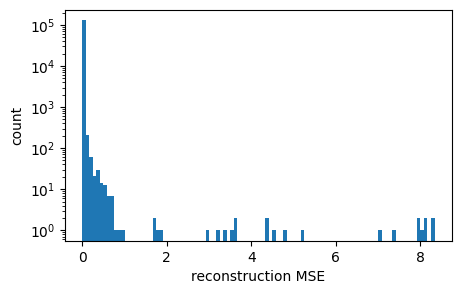

分數最高的 10 口： [78847, 61705, 61704, 85305, 61706, 78846, 85306, 100920, 125953, 61703]
分數最低的 5 口： [5363, 32616, 32432, 33171, 33170]


In [70]:
model.eval()
with torch.no_grad():
    Xt = torch.from_numpy(Xn)
    scores = ((model(Xt) - Xt) ** 2).mean(dim=(1, 2)).numpy()   # 每口呼吸一個分數
    Z = model.encoder(Xt).numpy()                                 # 每口呼吸的潛在向量 (N, 16)

plt.figure(figsize=(5, 3))
plt.hist(scores, bins=100); plt.yscale("log")
plt.xlabel("reconstruction MSE"); plt.ylabel("count"); plt.show()

order = np.argsort(scores)[::-1]
print("分數最高的 10 口：", ids[order[:10]].tolist())
print("分數最低的 5 口：", ids[order[-5:]].tolist())

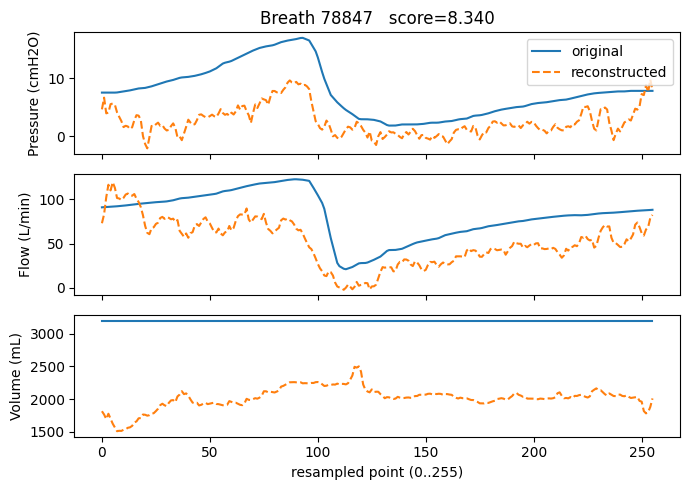

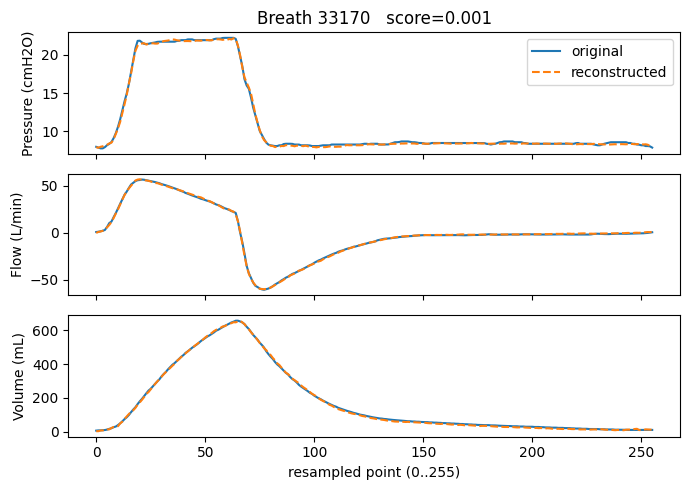

In [71]:
plot_recon(ids[order[0]])     # 最異常的一口
plot_recon(ids[order[-1]])    # 最正常的一口

## 下一步可以做的

* **只用正常呼吸訓練**：如果有標籤（例如 labels CSV），把 PVA 那幾口從 `tr_idx` 拿掉，分數的區分度會更好
* **用標籤驗證**：把 `scores` 跟標籤對起來，算 ROC-AUC，看分數能不能分出 PVA
* **用 `Z` 做分群**（KMeans / t-SNE / UMAP），看不同 PVA 類型會不會自己聚在一起
* **保留呼吸長度**：改成固定補零到同長度（而不是內插），或把 `lens` 跟 `Z` 一起丟給分類器
* **存模型**：`torch.save({"model": model.state_dict(), "mean": mean, "std": std}, "ae.pt")`

## 8. 用潛在向量 Z 分群

每口呼吸被 Encoder 壓成 16 個數字 `Z`（shape `(N, 16)`）。如果 autoencoder 學得好，
**長得像的呼吸，Z 也會靠在一起** → 對 Z 做分群，看會不會自然分出不同的呼吸型態（PVA）。

流程：
1. 先決定要分幾群（K）→ 用 elbow 與 silhouette 兩個指標
2. KMeans 分群，整理每群的統計
3. 把 16 維壓到 2 維畫圖（PCA / t-SNE）
4. 畫出每群的波形，用眼睛判斷每群是什麼

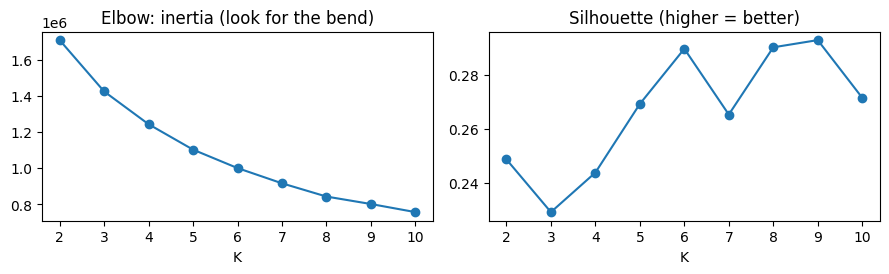

silhouette 最高的 K = 9


In [74]:
import os
from joblib.externals.loky.backend import context as _loky
_loky.physical_cores_cache = os.cpu_count()   # Windows 11 沒有 wmic，sklearn 查 CPU 核心數會噴一大串無害錯誤，直接告訴它
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

Zs = StandardScaler().fit_transform(Z)        # 16 個維度的尺度不同，先各自標準化

ks = list(range(2, 11))
inertia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=0).fit(Zs)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(Zs, km.labels_, sample_size=min(5000, len(Zs)), random_state=0))

fig, ax = plt.subplots(1, 2, figsize=(9, 3))
ax[0].plot(ks, inertia, "o-"); ax[0].set_title("Elbow: inertia (look for the bend)"); ax[0].set_xlabel("K")
ax[1].plot(ks, sil, "o-");     ax[1].set_title("Silhouette (higher = better)");      ax[1].set_xlabel("K")
plt.tight_layout(); plt.show()
print("silhouette 最高的 K =", ks[int(np.argmax(sil))])

### 8-1 KMeans 分群

silhouette 常常會建議很少的群（例如 2），但那通常只是把呼吸分成「兩大類正常型態」。
PVA 是少數，**要多分幾群，小群才有機會冒出來**，所以這裡先用 `K = 6`，看完結果可以自己調整。
表格欄位：`n` 幾口、`mean_score` 平均還原誤差（越高越可能異常）、`median_dur_s` 呼吸長度中位數（秒）、
`representative_id` 最靠近群中心的那一口（最能代表這群）。

In [90]:
K = 8                               # ← 想分幾群直接改；silhouette 建議值是 ks[int(np.argmax(sil))]

km = KMeans(n_clusters=K, n_init=10, random_state=0).fit(Zs)
cluster = km.labels_                 # 每口呼吸屬於哪一群，shape (N,)
dist = km.transform(Zs)              # 每口到每個群中心的距離，shape (N, K)

def cluster_ids(c, n=10):
    """第 c 群中，最靠近群中心的 n 口 breath_id（最典型的）"""
    m = cluster == c
    return ids[m][np.argsort(dist[m, c])][:n].tolist()

summary = pd.DataFrame({
    "n":                 np.bincount(cluster, minlength=K),
    "mean_score":        [scores[cluster == c].mean() for c in range(K)],
    "median_dur_s":      [np.median(lens[cluster == c]) / 100 for c in range(K)],
    "representative_id": [cluster_ids(c, 1)[0] for c in range(K)],
}).rename_axis("cluster")
summary.round({"mean_score": 4, "median_dur_s": 2})

,n,mean_score,median_dur_s,representative_id
cluster,,,,
0,18224,0.0095,4.06,64473
1,6783,0.0187,1.70,51655
2,38246,0.0028,4.24,48618
3,12935,0.0026,4.29,31866
4,28655,0.0028,3.57,56151
5,11889,0.0076,2.90,103047
6,5818,0.0066,4.29,66221
7,8598,0.0080,4.29,108176


### 8-2 畫成 2D 散佈圖

16 維沒辦法直接畫，所以壓成 2 維：
* **PCA**：線性投影，快、穩定，但分得比較不開
* **t-SNE**：非線性，比較能看出一團一團，但**群跟群之間的距離沒有意義**，只看「誰跟誰同一團」

同一張 t-SNE 用四種顏色看：分群結果 / 異常分數 / 呼吸順序（時間）/ 呼吸長度。
`KNOWN` 可以填你已經確認過的呼吸，會用星號標在圖上（必須是**這次 waves 裡**的 breath_id）。

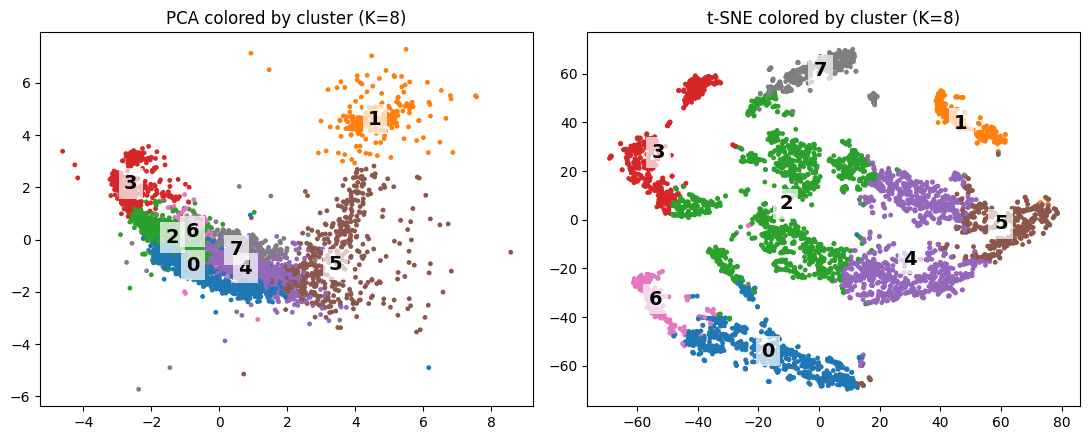

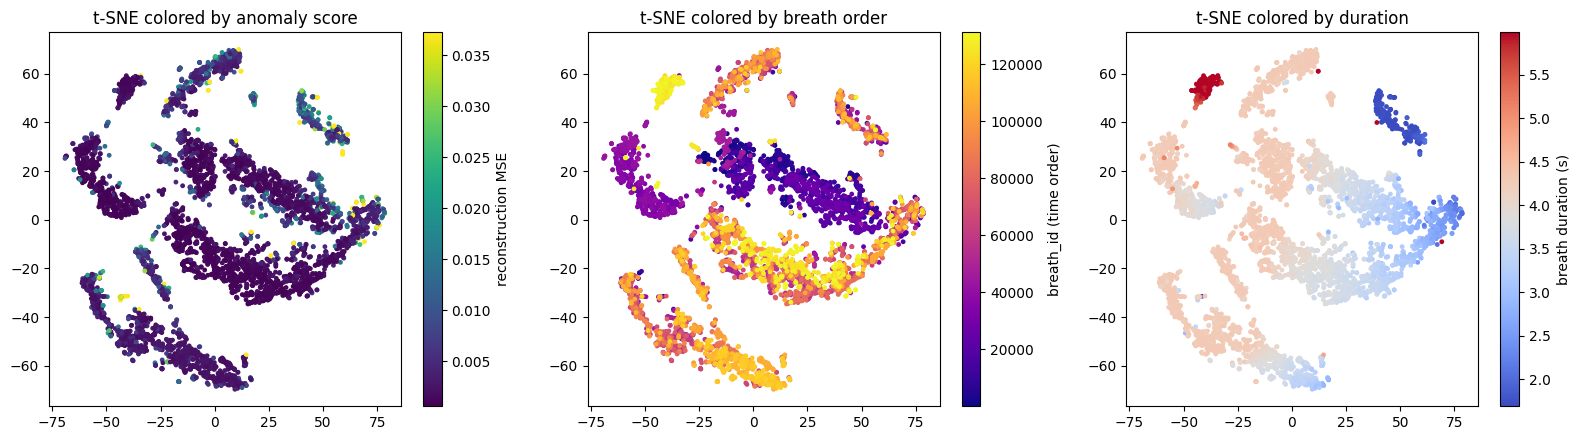

In [92]:
KNOWN = {}   # 例如 {"double trigger": [1466], "ineffective trigger": [1640]}

MAX_PTS = 5000                                    # t-SNE 點太多會很慢，超過就隨機抽樣
rng = np.random.default_rng(0)
sub = np.arange(len(Zs)) if len(Zs) <= MAX_PTS else np.sort(rng.choice(len(Zs), MAX_PTS, replace=False))
known_k = {name: [k for k in np.where(np.isin(ids, b))[0]] for name, b in KNOWN.items()}
sub = np.union1d(sub, [k for v in known_k.values() for k in v]).astype(int)   # 已知的那幾口一定要畫到

emb_pca  = PCA(2, random_state=0).fit_transform(Zs[sub])
emb_tsne = TSNE(2, perplexity=30, init="pca", random_state=0).fit_transform(Zs[sub])
pos = {k: i for i, k in enumerate(sub)}           # 原始索引 -> 在 sub 裡的位置

def mark_known(a, emb):
    for name, ks_ in known_k.items():
        p = [pos[k] for k in ks_]
        a.scatter(emb[p, 0], emb[p, 1], marker="*", s=250, edgecolor="k", linewidth=1, label=name)
    if known_k: a.legend(fontsize=8)

fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
for a, emb, title in [(ax[0], emb_pca, "PCA"), (ax[1], emb_tsne, "t-SNE")]:
    sc = a.scatter(emb[:, 0], emb[:, 1], c=cluster[sub], cmap="tab10", s=6, vmin=0, vmax=9)
    for c in range(K):                            # 在每群中間寫群號
        m = cluster[sub] == c
        a.text(*np.median(emb[m], axis=0), str(c), fontsize=14, weight="bold", ha="center", va="center",
               bbox=dict(facecolor="white", alpha=0.7, edgecolor="none"))
    mark_known(a, emb); a.set_title(f"{title} colored by cluster (K={K})")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
sc = ax[0].scatter(emb_tsne[:, 0], emb_tsne[:, 1], c=scores[sub], cmap="viridis", s=6,
                   vmax=np.percentile(scores, 99))
plt.colorbar(sc, ax=ax[0], label="reconstruction MSE"); ax[0].set_title("t-SNE colored by anomaly score")
sc = ax[1].scatter(emb_tsne[:, 0], emb_tsne[:, 1], c=ids[sub], cmap="plasma", s=6)
plt.colorbar(sc, ax=ax[1], label="breath_id (time order)"); ax[1].set_title("t-SNE colored by breath order")
sc = ax[2].scatter(emb_tsne[:, 0], emb_tsne[:, 1], c=lens[sub] / 100, cmap="coolwarm", s=6,
                   vmin=np.percentile(lens, 1) / 100, vmax=np.percentile(lens, 99) / 100)
plt.colorbar(sc, ax=ax[2], label="breath duration (s)"); ax[2].set_title("t-SNE colored by duration")
for a in ax: mark_known(a, emb_tsne)
plt.tight_layout(); plt.show()

### 8-3 每一群的波形長什麼樣子

每一欄是一群：灰色細線是群裡隨機 30 口，黑色粗線是全群平均。
用這張圖判斷每群是「正常」「double trigger」「ineffective trigger」…或只是「設定不同的正常呼吸」。

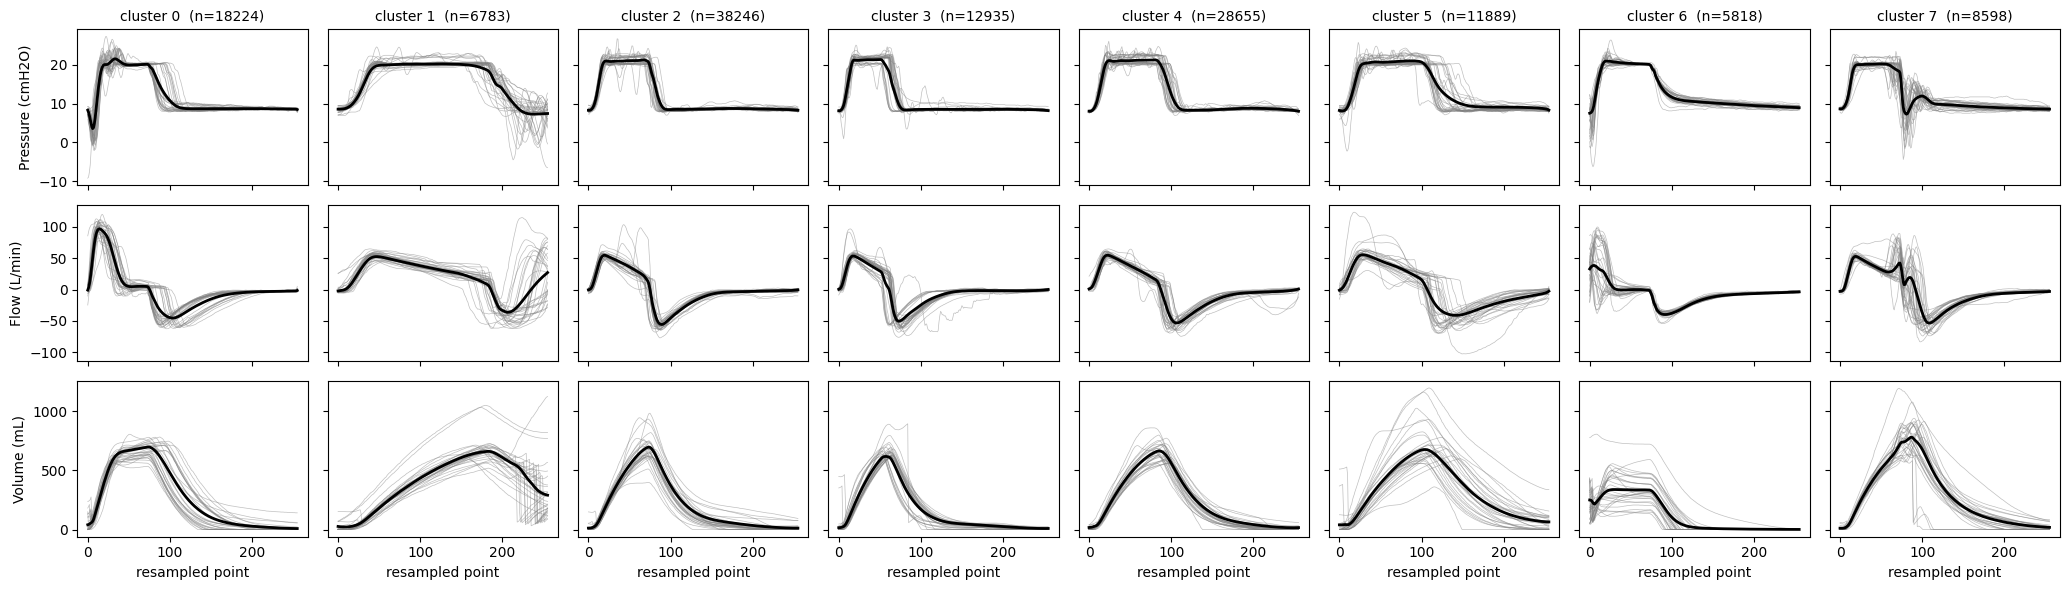

cluster 0 最典型的 10 口： [64473, 109512, 51043, 64160, 73626, 108085, 115980, 64479, 51305, 112242]
cluster 1 最典型的 10 口： [51655, 121921, 74249, 60156, 57865, 51431, 56815, 57148, 50907, 60334]
cluster 2 最典型的 10 口： [48618, 92581, 44160, 92572, 98517, 92597, 92905, 121655, 92466, 44119]
cluster 3 最典型的 10 口： [31866, 31484, 31298, 42281, 31483, 31858, 31304, 31874, 31863, 31387]
cluster 4 最典型的 10 口： [56151, 55871, 76477, 95387, 56022, 75489, 94821, 94903, 55961, 55645]
cluster 5 最典型的 10 口： [103047, 87926, 109900, 67488, 90512, 110110, 70809, 51035, 71114, 52487]
cluster 6 最典型的 10 口： [66221, 103708, 92274, 73957, 98074, 53639, 52894, 69640, 99110, 107044]
cluster 7 最典型的 10 口： [108176, 71149, 108242, 107110, 66501, 53916, 59292, 53886, 66715, 55383]


In [94]:
fig, ax = plt.subplots(3, K, figsize=(2.6 * K, 6), sharex=True, sharey="row", squeeze=False)
for c in range(K):
    m = np.where(cluster == c)[0]
    pick = rng.choice(m, min(30, len(m)), replace=False)
    for i, name in enumerate(CH):
        ax[i, c].plot(X[pick, i].T, color="gray", lw=0.5, alpha=0.5)
        ax[i, c].plot(X[m, i].mean(axis=0), color="k", lw=2)
        if c == 0: ax[i, c].set_ylabel(name)
    ax[0, c].set_title(f"cluster {c}  (n={len(m)})", fontsize=10)
for c in range(K): ax[-1, c].set_xlabel("resampled point")
plt.tight_layout(); plt.show()

for c in range(K):
    print(f"cluster {c} 最典型的 10 口：", cluster_ids(c))

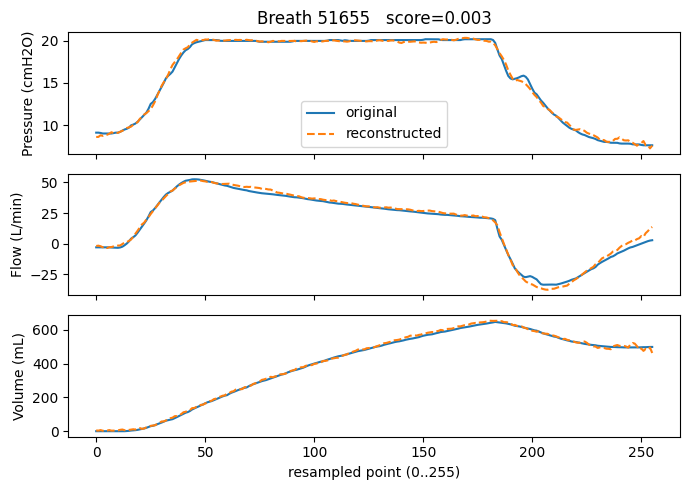

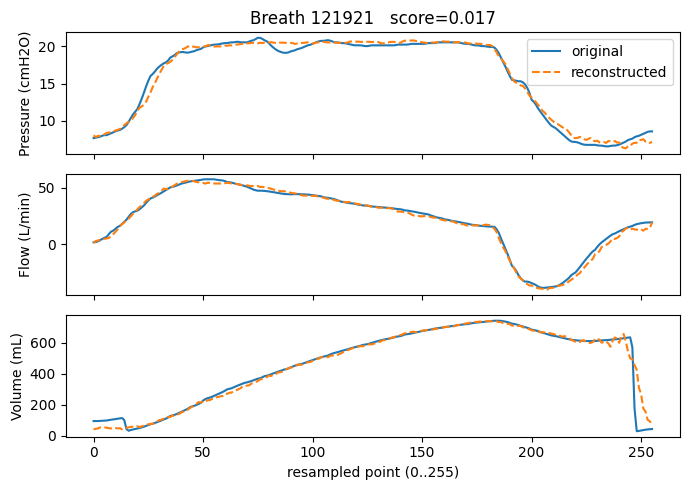

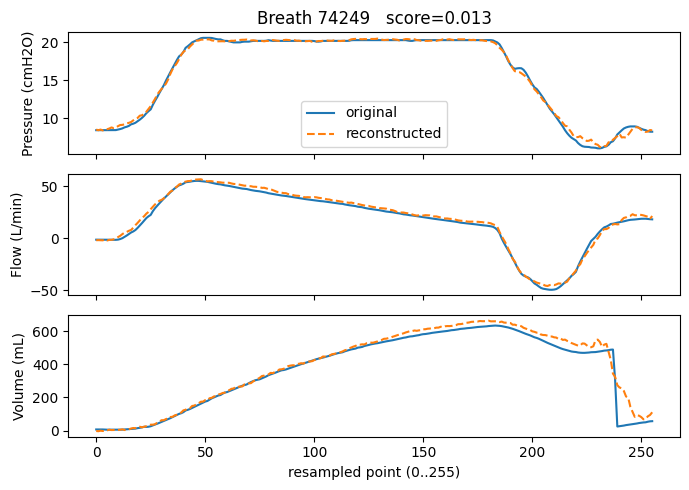

In [95]:
# 挑一群仔細看：畫出最典型的幾口（原始 vs. 還原），換數字就能看別群
c = int(summary["mean_score"].idxmax())          # 預設看平均異常分數最高的那群
for bid in cluster_ids(c, 3):
    plot_recon(bid)

### 怎麼解讀

* **分群是非監督的**：KMeans 只是把「長得像的」放一起，群號 0、1、2… 沒有意義，要靠 8-3 的波形圖去命名。
* **群可能是「設定」而不是「PVA」**：同一個病人在不同時段呼吸器設定（壓力、潮氣量）會變，
  t-SNE 用 *breath order* 上色時，如果一群剛好對應一段連續時間，那它多半是「設定不同」而不是異常。
* **PVA 通常是少數**：它們常常不會自成一大群，而是散落在邊緣、或擠成一個小群 → 對照 *anomaly score* 那張圖，
  分數高、又在邊緣的點最值得看。
* **群可能只是「呼吸長短」**：每口都被內插成 256 點，長呼吸的吸氣段會被擠到前面、短呼吸的吸氣段會被拉長，
  所以 Z 很容易依「呼吸長度 / 吸吐比」分群 → 對照 *duration* 那張圖確認。
* **有標籤之後**：把確認過的 breath_id 填進 `KNOWN`，看同一類 PVA 的星號是否落在同一團，就知道這個方法分不分得出來。